### E-Commerce Review Intelligence System

**MBA Business Analytics Assignment**  
**Dataset:** Amazon Fine Food Reviews

This notebook develops an end-to-end review intelligence workflow that translates unstructured customer feedback into actionable product and customer-experience insights.

#### Business Problem

E-commerce leaders receive thousands of product reviews, but manually reading them does not scale. The business needs a reliable way to identify how customers feel, understand the themes behind that feedback, and prioritize products where negative experiences create the greatest commercial risk.

**Decision question:** Which products and customer-experience themes should management investigate first to protect customer satisfaction and future revenue?



#### Dataset Description

This analysis uses the **Amazon Fine Food Reviews dataset.** Each record contains a product identifier, a 1-5 star rating, a review summary, and the full review text. Ratings provide a practical sentiment proxy: scores 1-2 are negative, 3 is neutral, and 4-5 are positive.



| # | Column | Description |
|---:|---|---|
| 1 | `Id` | Unique row or review identifier |
| 2 | `ProductId` | Unique identifier for the food or gourmet product |
| 3 | `UserId` | Unique identifier for the reviewer |
| 4 | `ProfileName` | Name or nickname of the reviewer |
| 5 | `HelpfulnessNumerator` | Number of users who found the review helpful |
| 6 | `HelpfulnessDenominator` | Total number of votes on whether the review was helpful |
| 7 | `Score` | Star rating from 1 to 5 |
| 8 | `Time` | Timestamp of the review |
| 9 | `Summary` | Short text summary or title of the review |
| 10 | `Text` | Full text content of the customer review |

In [1]:
# Experiment 1                 Experiment 2                 Experiment 3

# TF-IDF                       Word Embeddings              Pretrained DistilBERT
#    ↓                              ↓                              ↓
# Logistic Regression             LSTM                       Self-Attention
#    ↓                              ↓                              ↓
# Sentiment                     Sentiment                       Sentiment

# Statistical NLP             Sequential Deep Learning      Transformer NLP

In [2]:
# `Experiment 1`
# "The food is not very good"
#         ↓ TF-IDF
# Large sparse vector
#         ↓
# Logistic Regression
#         ↓
# Predicted Sentiment

#  ---------------------------------------------------------

# `Experiment 2`
# "The food is not very good"
#        ↓ Word tokenizer
# [15, 83, 9, 37, 24, 51]
#        ↓ Embedding
# Dense word vectors
#        ↓ LSTM
# Sequential representation
#        ↓ Dense + Softmax
# Predicted Sentiment
# Negative / Neutral / Positive

#  ---------------------------------------------------------


In [3]:
# `Experiment 3`
# "The food is not very good"
#            ↓
# DistilBERT Tokenizer
#            ↓
# Subword Tokens
# + Attention Mask
#            ↓
# Pretrained DistilBERT
#    Transformer Layers
#            ↓
# Self-Attention
#            ↓
# Contextual Representation
#            ↓
# Classification Head
#            ↓
# Negative / Neutral / Positive

#  ---------------------------------------------------------

In [4]:
#                     RAW REVIEWS
#                          │
#                          ▼
#               ┌────────────────────┐
#               │ Exploratory Data   │
#               │ Analysis           │
#               └─────────┬──────────┘
#                         │
#                         ▼
#              Cleaning + Label Creation
#                         │
#               ┌─────────┴──────────┐
#               │                    │
#               ▼                    ▼
#       CLASSICAL NLP           TRANSFORMER
#               │                    │
#         TF-IDF / LSTM          Tokenizer
#           ┌───┴───┐                │
#           ▼       ▼                ▼
#      Logistic                     DistilBERT
#      Regression                     │
#           │       │                 │
#           └───────┴────────┬────────┘
#                            ▼
#                    MODEL EVALUATION
#                            │
#       ┌────────────────────┼──────────────────┐
#       ▼                    ▼                  ▼
#    Accuracy             Macro F1        Confusion Matrix
#                            │
#                            ▼
#                      ERROR ANALYSIS
#                            │
#                            ▼
#                       BEST MODEL
#                            │
#                            ▼
#                        BERTopic
#                            │
#                            ▼
#                 TOPIC × SENTIMENT
#                            │
#                            ▼
#                    BUSINESS INSIGHTS
#                            │
#                ┌───────────┼────────────┐
#                ▼           ▼            ▼
#              Product     Marketing     Service
#            Improvement    Insights    Improvement

1. Importing Libraries

In [5]:
!python3 -m pip install torch transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn

In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import random

import torch


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [8]:
from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    DataCollatorWithPadding
)

In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device: ", device)

Device:  mps


In [10]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

2. Importing Datasets

In [11]:
df = pd.read_csv("./Reviews.csv")

In [12]:
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")


Rows: 568454, Columns: 10


3. Examining Dataset

In [13]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [14]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


Missing Values

In [16]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [17]:
df = df.dropna(subset=["Summary"])
df = df.reset_index(drop=True)

In [18]:
print("Total duplicated rows in the dataframe:", df.duplicated().sum())

Total duplicated rows in the dataframe: 0


In [19]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29744
3     42638
4     80655
5    363122
Name: count, dtype: int64

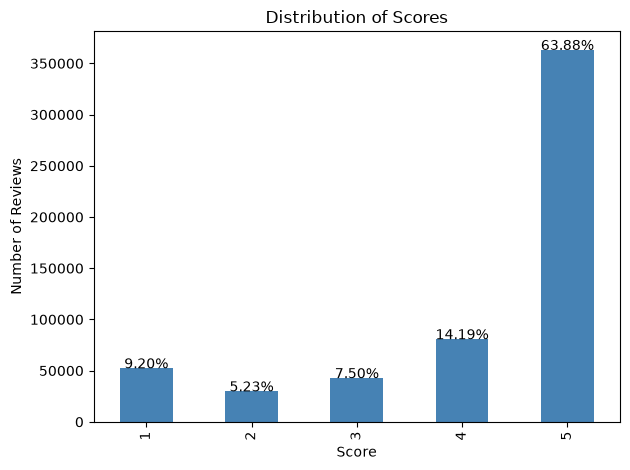

In [20]:
# Plot the distribution of review scores
df["Score"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Score"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

4. Convert Rating into Sentiment
* [1, 2] -> Negative
* [ 3  ]    -> Neutral
* [4, 5] -> Positive

In [21]:
def create_sentiment(score: int) -> str:
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

In [22]:
df["Sentiment"] = df["Score"].apply(create_sentiment)

In [23]:
df[["Score", "Sentiment"]].head(10)

,Score,Sentiment
0,5,Positive
1,1,Negative
2,4,Positive
3,2,Negative
4,5,Positive
5,4,Positive
6,5,Positive
7,5,Positive
8,5,Positive
9,5,Positive


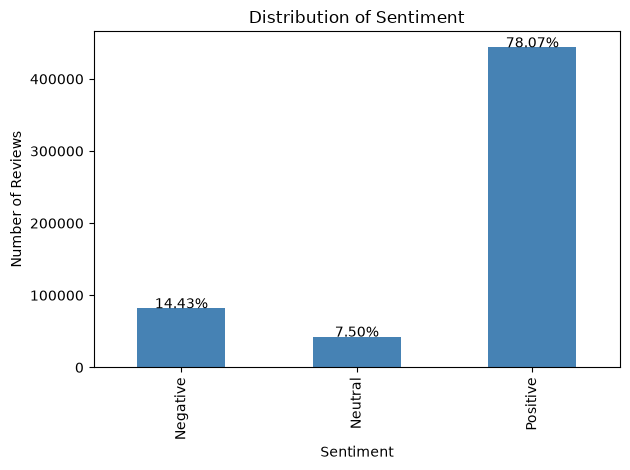

In [24]:
# Plot the distribution of Sentiment
df["Sentiment"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Sentiment"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )


plt.title("Distribution of Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Inference: Class Highly Imbalanced -
* Positive - 78 %
* Neutral - 7.5%
* Negative - 14.5 %

Merging Summary with Text in Review Column appended by comma(',')

In [25]:
df["Review"] = (df["Summary"].fillna("") + " , " + df["Text"].fillna(""))
df["Review"].head()

0    Good Quality Dog Food , I have bought several ...
1    Not as Advertised , Product arrived labeled as...
2    "Delight" says it all , This is a confection t...
3    Cough Medicine , If you are looking for the se...
4    Great taffy , Great taffy at a great price.  T...
Name: Review, dtype: str

5. Basic Text Preprocessing

In [26]:
import re

In [27]:
def clean_text_transformer(text: str) -> str:
    text = str(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Normalize repeated whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [ ]:
df["Review"] = df["Review"].apply(clean_text_transformer)

* Inference : Stopwords should not be removed as it will remove the sentiment in the review comments

In [30]:
# TensorFlow works more naturally with numeric classes.
label_map = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

In [31]:
df["label"] = df["Sentiment"].map(label_map)

In [32]:
df[["Sentiment", "label"]].head()

,Sentiment,label
0,Positive,2
1,Negative,0
2,Positive,2
3,Negative,0
4,Positive,2


In [33]:
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

6. Train / Validation / Test Split

* 70% training
* 15% validation
* 15% testing

Experiment 3: Transformer

In [34]:
train_df, temp_df = train_test_split(
    df[["Review", "label"]],
    test_size=0.3,
    random_state=SEED,
    stratify=df["label"]
)

In [36]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df["label"]
)

In [37]:
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

In [38]:
print("Training set size:", len(train_df))
print("Validation set size:", len(val_df))
print("Test set size:", len(test_df))

Training set size: 397898
Validation set size: 85264
Test set size: 85265


#### 7. Choosing DistilBERT as Transformer Model

In [ ]:
!python3 -c 'from huggingface_hub import snapshot_download; models=["distilbert-base-uncased"]; [print(f"Downloading {m}...") or snapshot_download(repo_id=m) for m in models]; print("Downloads complete.")'

In [39]:
MODEL_NAME = "distilbert-base-uncased"

### Tokenization 
> Tokenizer learns Vocabulary

> Sample Tokenization Process

In [40]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

OSError: Can't load config for 'distilbert-base-uncased'. If you were trying to load it from 'https://huggingface.co/models', make sure you don't have a local directory with the same name. Otherwise, make sure 'distilbert-base-uncased' is the correct path to a directory containing a config.json file

OOV = Out Of Vocabulary.

In [ ]:
sample_text = train_df["Review"].iloc[50]
print(sample_text)

In [ ]:
tokens = tokenizer.tokenize(sample_text)
print(tokens)

In [ ]:
encoded = tokenizer(
    sample_text,
    truncation=True,
    max_length=256
)

In [ ]:
print(encoded["input_ids"])

Each tokenizer token corresponds to a vocabulary ID.

In [ ]:
print(encoded["attention_mask"])

The attention mask tells the model which positions contain actual sequence tokens versus padding:
> 1 → real token position

> 0 → padding position

#### Tokenization Length Calculation 

In [41]:
token_lengths = train_df["Review"].apply(
    lambda x: len(
        tokenizer.encode(
            x,
            add_special_tokens=True,
            truncation=False
        )
    )
)

NameError: name 'tokenizer' is not defined

In [42]:
token_lengths.describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

NameError: name 'token_lengths' is not defined

In [43]:
plt.figure(figsize=(10, 5))

sns.histplot(
    token_lengths,
    bins=50
)

# Show percentage on the bars
total = len(token_lengths)
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.xlabel("Number of DistilBERT Tokens")
plt.ylabel("Number of Reviews")
plt.title(
    "DistilBERT Token Length Distribution"
)

plt.show()

NameError: name 'token_lengths' is not defined

<Figure size 1000x500 with 0 Axes>

In [44]:
MAX_LENGTH = 256

Convert DataFrames into Hugging Face Datasets

In [45]:
train_dataset = Dataset.from_pandas(train_df)

val_dataset = Dataset.from_pandas(val_df)

test_dataset = Dataset.from_pandas(test_df)

In [46]:
train_dataset

Dataset({
    features: ['Review', 'label'],
    num_rows: 397898
})

Creating Tokenizer Function

In [47]:
def tokenize_function(batch):
    return tokenizer(
        batch["Review"],
        truncation=True,
        max_length=MAX_LENGTH
    )

Tokenize all Splits

In [48]:
train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/397898 [00:00<?, ? examples/s]

NameError: name 'tokenizer' is not defined

In [49]:
print(train_tokenized[0])

NameError: name 'train_tokenized' is not defined

#### Dynamic Padding -
dynamic padding pads each batch only to the longest sequence within that batch.

In [50]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

NameError: name 'tokenizer' is not defined

Load Pretrained DistilBERT

In [51]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

OSError: Can't load config for 'distilbert-base-uncased'. If you were trying to load it from 'https://huggingface.co/models', make sure you don't have a local directory with the same name. Otherwise, make sure 'distilbert-base-uncased' is the correct path to a directory containing a config.json file

#### Define Evaluation Metrics

In [52]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average='macro',
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

#### Training Model

In [ ]:
training_args = TrainingArguments(
    output_dir='./distilbert_sentiment',
    learning_rate=2e-5, # lower bcoz we're fine-tuning pretrained weights.

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01, # adds regularization to reduce overfitting.

    evaluation_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_steps=100,

    save_total_limit=2
)

In [55]:
trainer = Trainer(
    model=MODEL_NAME,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

NameError: name 'train_tokenized' is not defined

In [ ]:
trainer.train()

#### Evaluate on Validation data

In [56]:
val_results = trainer.evaluate(
    val_tokenized
)

print(val_results)

NameError: name 'trainer' is not defined

In [ ]:
test_results = trainer.evaluate(
    test_tokenized
)

print(test_results)

In [ ]:
pred_output = trainer.predict(
    test_tokenized
)

In [57]:
test_logits = pred_output.predictions

NameError: name 'pred_output' is not defined

Visualise Accuracy

In [58]:
y_pred = np.argmax(
    test_logits,
    axis=1
)

NameError: name 'test_logits' is not defined

Model Evaluation

In [59]:
y_test = test_df["label"].values

In [ ]:
target_names = [
    "Negative",
    "Neutral",
    "Positive"
]


Classification Report

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
))

Confusion Matrix

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT Sentiment Classification Confusion Matrix")

plt.show()

Convert Logits to Probabilities

In [60]:
probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()

NameError: name 'test_logits' is not defined

In [61]:
probabilities[0]

NameError: name 'probabilities' is not defined

#### Error Analysis

In [62]:
results = pd.DataFrame({
    "Review": test_df["Review"].values,
    "Actual": y_test,
    "Predicted": y_pred,
    "Confidence": probabilities.max(axis=1)
})

NameError: name 'y_pred' is not defined

In [ ]:
results["Actual"] = (
    results["Actual"]
    .map(id2label)
)

results["Predicted"] = (
    results["Predicted"]
    .map(id2label)
)

In [ ]:
error = results[
    results["Actual"] != results["Predicted"]
]

In [ ]:
error.sort_values(
    by="Confidence",
    ascending=False
).head(20)

Running Test on Sample Sentences

In [63]:
def predict_sentiment(text):

    text = clean_text_transformer(text)

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True
    )

    model_device = next(
        model.parameters()
    ).device

    inputs = {
        key: value.to(model_device)
        for key, value in inputs.items()
    }

    model.eval()

    with torch.no_grad():

        output = model(
            **inputs
        )

    probs = torch.softmax(
        output.logits,
        dim=1
    )[0]

    predicted_id = int(
        torch.argmax(probs)
    )

    return {
        "sentiment":
            id2label[predicted_id],

        "confidence":
            float(probs[predicted_id]),

        "probabilities": {
            id2label[i]: float(probs[i])
            for i in range(3)
        }
    }

In [64]:
predict_sentiment(
    "Excellent product and very fast delivery"
)

NameError: name 'tokenizer' is not defined

In [65]:
predict_sentiment(
    "Absolutely awful quality and I would never buy this again"
)

NameError: name 'tokenizer' is not defined

In [66]:
predict_sentiment(
    "The food tastes amazing but the package arrived damaged and late"
)

NameError: name 'tokenizer' is not defined

Saving the Model

In [67]:
trainer.save_model("./final_distilbert_sentiment")

NameError: name 'trainer' is not defined

In [68]:
tokenizer.save_pretrained("./final_distilbert_sentiment")

NameError: name 'tokenizer' is not defined

In [69]:
experiment_3_results = {
    "Model":
        "Fine-tuned DistilBERT",

    "Accuracy":
        test_results["eval_accuracy"],

    "Macro Precision":
        test_results["eval_macro_precision"],

    "Macro Recall":
        test_results["eval_macro_recall"],

    "Macro F1":
        test_results["eval_macro_f1"]
}

experiment_3_results

NameError: name 'test_results' is not defined